# 04 — Ridge, Random Forest et Extra Trees : comparaison des prévisions

**Question** : au 1er mai, avec ce qu'on sait déjà (surface de l'an dernier, débits, nitrates et flux
d'azote de janvier à avril, météo de mars-avril), quelle surface d'échouage prévoir pour la saison ?

**Règle du jeu** (fenêtre glissante) : pour prévoir l'année N, chaque modèle n'apprend que sur les
années < N. On teste ainsi 2010 à 2022, sur les 7 baies. La « réalité » est le cumul CEVA.

On compare trois modèles et deux références naïves :
| | Principe |
|---|---|
| **Ridge** | formule linéaire pondérée (en log), coefficients bridés |
| **Random Forest** | moyenne de 300 arbres de décision, chacun sur un tirage des données |
| **Extra Trees** | comme la forêt, mais coupures tirées au hasard : plus lisse |
| *Année précédente* | « même surface que l'an dernier » |
| *Moyenne* | « surface habituelle de la baie » |

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

RACINE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RACINE / "src"))
from algathon.baseline_annuel import JEUX_DE_VARIABLES, evaluer, scores, importance_hors_echantillon
from algathon.series_annuelles import charger_config

table = pd.read_csv(RACINE / "data" / "processed" / "baies_annuel.csv")
noms_baies = {k: b["nom"].split("(")[0].strip() for k, b in charger_config()["baies"].items()}
VARIABLES = JEUX_DE_VARIABLES["prevision_1er_mai"]

# ~1 min : prédictions hors échantillon de chaque modèle, année par année
pred = evaluer(table, VARIABLES, methode="glissante")
MODELES = {"ridge": ("Ridge", "#457b9d"), "random_forest": ("Random Forest", "#2a9d8f"),
           "extra_trees": ("Extra Trees", "#e76f51")}
REF = {"annee_precedente": ("Comme l'an dernier", "#999999")}
print(len(pred), "prédictions,", pred["annee"].min(), "-", pred["annee"].max())

90 prédictions, 2010 - 2022


## 1. Scores globaux

In [2]:
s = scores(pred).drop(columns="n")
s.columns = ["erreur moyenne (ha)", "erreur relative", "gain vs an dernier"]
s = s.rename(index={**{k: v[0] for k, v in MODELES.items()}, "annee_precedente": "Comme l'an dernier",
                    "moyenne": "Moyenne de la baie", "gradient_boosting": "Gradient boosting"})
s.style.format({"erreur moyenne (ha)": "{:.0f}", "erreur relative": "{:.1%}", "gain vs an dernier": "{:+.1%}"}) \
    .background_gradient(subset=["gain vs an dernier"], cmap="RdYlGn", vmin=-0.15, vmax=0.15)

,erreur moyenne (ha),erreur relative,gain vs an dernier
methode,,,
Extra Trees,62,49.1%,+11.3%
Random Forest,64,49.7%,+10.1%
Ridge,73,53.4%,+3.4%
Comme l'an dernier,77,55.3%,+0.0%
Moyenne de la baie,76,57.3%,-3.7%
Gradient boosting,77,58.2%,-5.2%


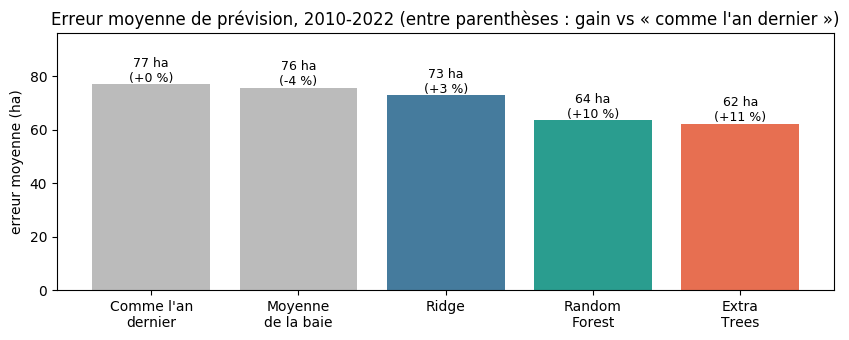

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ordre = ["annee_precedente", "moyenne", "ridge", "random_forest", "extra_trees"]
r = scores(pred).loc[ordre]
etiq = ["Comme l'an\ndernier", "Moyenne\nde la baie", "Ridge", "Random\nForest", "Extra\nTrees"]
coul = ["#bbbbbb", "#bbbbbb", MODELES["ridge"][1], MODELES["random_forest"][1], MODELES["extra_trees"][1]]
barres = ax.bar(etiq, r["mae_ha"].values, color=coul)
for b, v, g in zip(barres, r["mae_ha"].values, r["gain_vs_n_1"].values):
    ax.text(b.get_x() + b.get_width() / 2, v + 1, "%.0f ha\n(%+.0f %%)" % (v, 100 * g), ha="center", fontsize=9)
ax.set_ylabel("erreur moyenne (ha)"); ax.set_ylim(0, r["mae_ha"].max() * 1.25)
ax.set_title("Erreur moyenne de prévision, 2010-2022 (entre parenthèses : gain vs « comme l'an dernier »)")
fig.tight_layout()

## 2. Prévisions et réalité, baie par baie

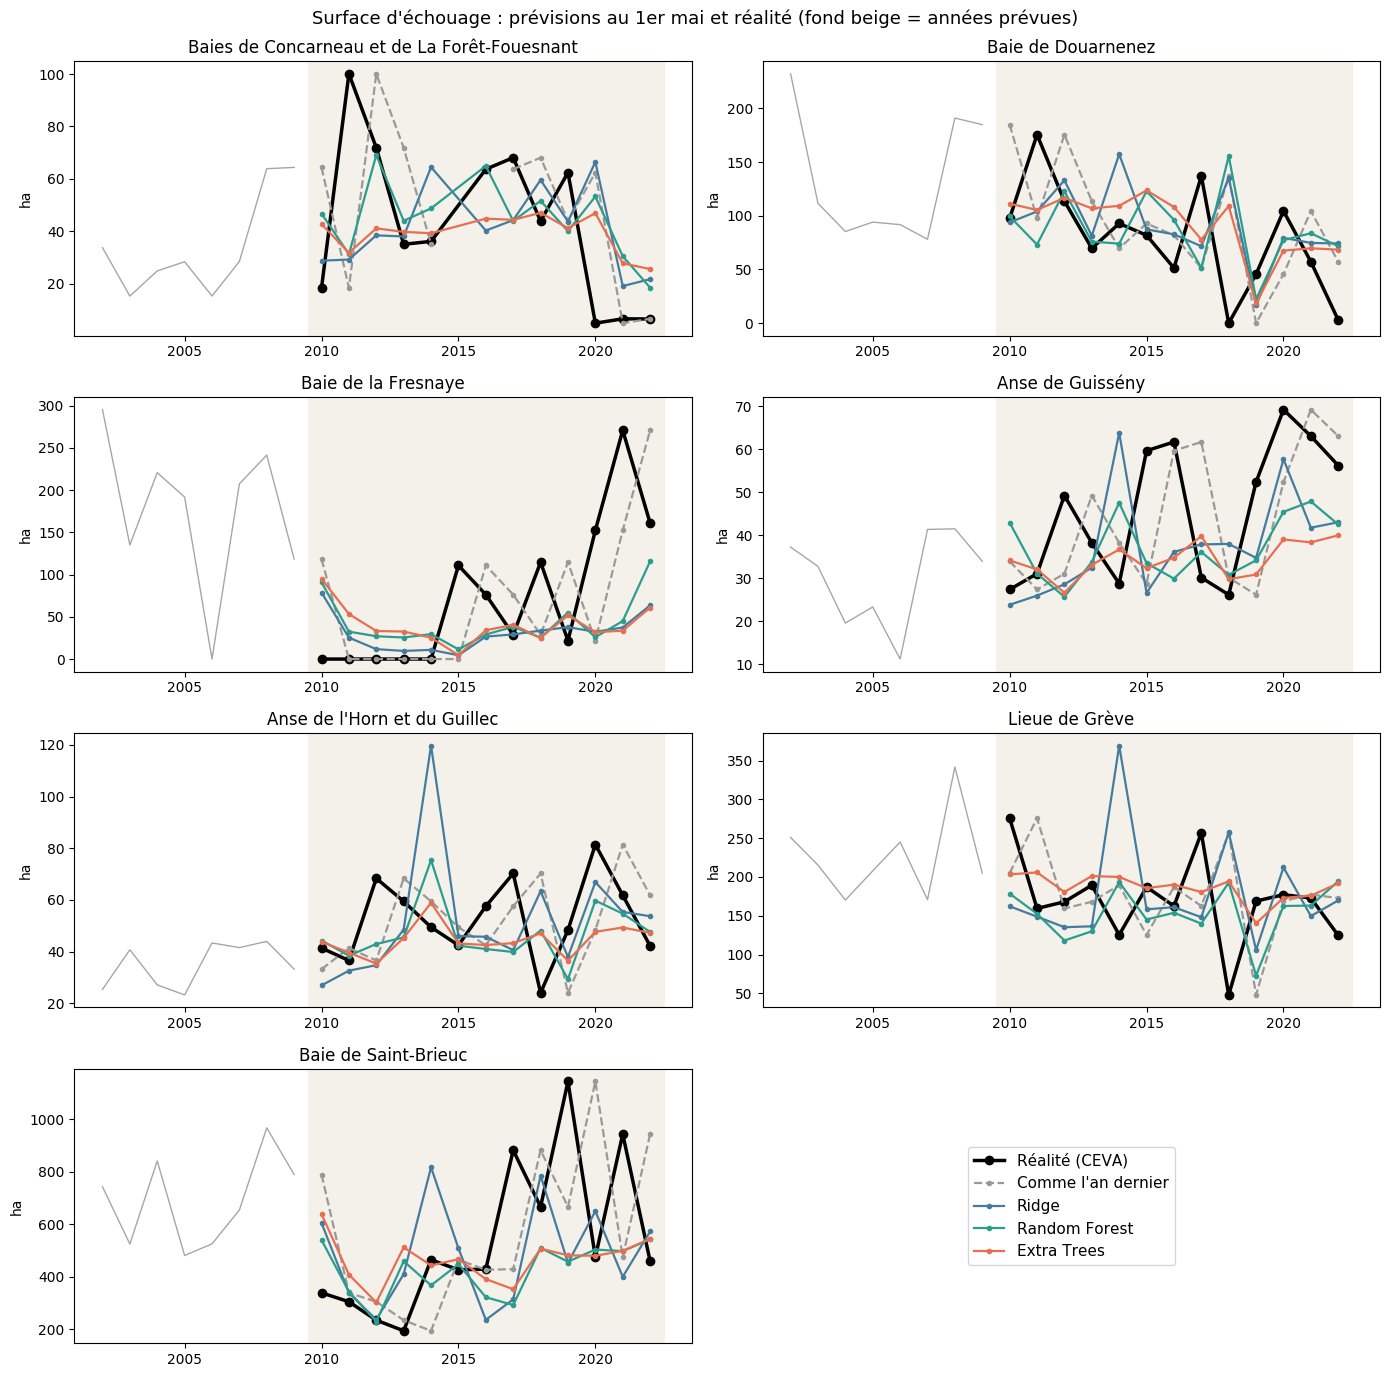

In [4]:
fig, axes = plt.subplots(4, 2, figsize=(14, 14))
for ax, (b, g) in zip(axes.flat, pred.groupby("baie")):
    g = g.sort_values("annee")
    hist = table[(table["baie"] == b) & (table["annee"] < g["annee"].min())]
    ax.plot(hist["annee"].values, hist["surface_ha"].values, color="black", lw=1, alpha=0.35)
    ax.plot(g["annee"].values, g["vrai"].values, color="black", lw=2.5, marker="o", label="Réalité (CEVA)")
    for k, (nom, c) in {**REF, **MODELES}.items():
        ax.plot(g["annee"].values, g["pred_" + k].values, color=c, lw=1.6, marker=".",
                ls="--" if k in REF else "-", label=nom)
    ax.axvspan(g["annee"].min() - 0.5, g["annee"].max() + 0.5, color="#f4f1ea", zorder=0)
    ax.set_title(noms_baies[b]); ax.set_ylabel("ha")
axes.flat[-1].axis("off")
h, l = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(h, l, loc="center", fontsize=11)
fig.suptitle("Surface d'échouage : prévisions au 1er mai et réalité (fond beige = années prévues)", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.97])

## 3. Prévu contre réel

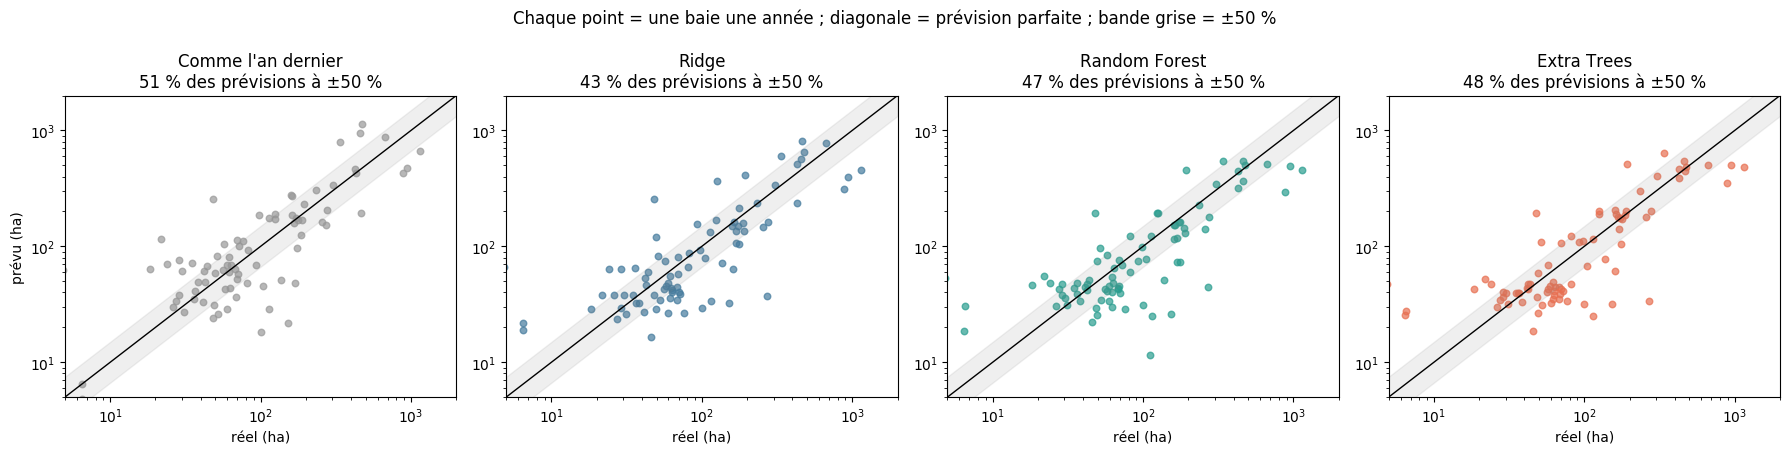

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
for ax, (k, (nom, c)) in zip(axes, {**REF, **MODELES}.items()):
    x, y = pred["vrai"].values, pred["pred_" + k].values
    ok = ~np.isnan(y)
    ax.scatter(x[ok], y[ok], color=c, alpha=0.7, s=22)
    lim = [5, 2000]
    ax.plot(lim, lim, color="black", lw=1)
    ax.fill_between(lim, [v / 1.5 for v in lim], [v * 1.5 for v in lim], color="grey", alpha=0.12)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
    dans = np.mean((y[ok] >= x[ok] / 1.5) & (y[ok] <= x[ok] * 1.5))
    ax.set_title("%s\n%.0f %% des prévisions à ±50 %%" % (nom, 100 * dans))
    ax.set_xlabel("réel (ha)")
axes[0].set_ylabel("prévu (ha)")
fig.suptitle("Chaque point = une baie une année ; diagonale = prévision parfaite ; bande grise = ±50 %", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.92])

## 4. Erreur par baie

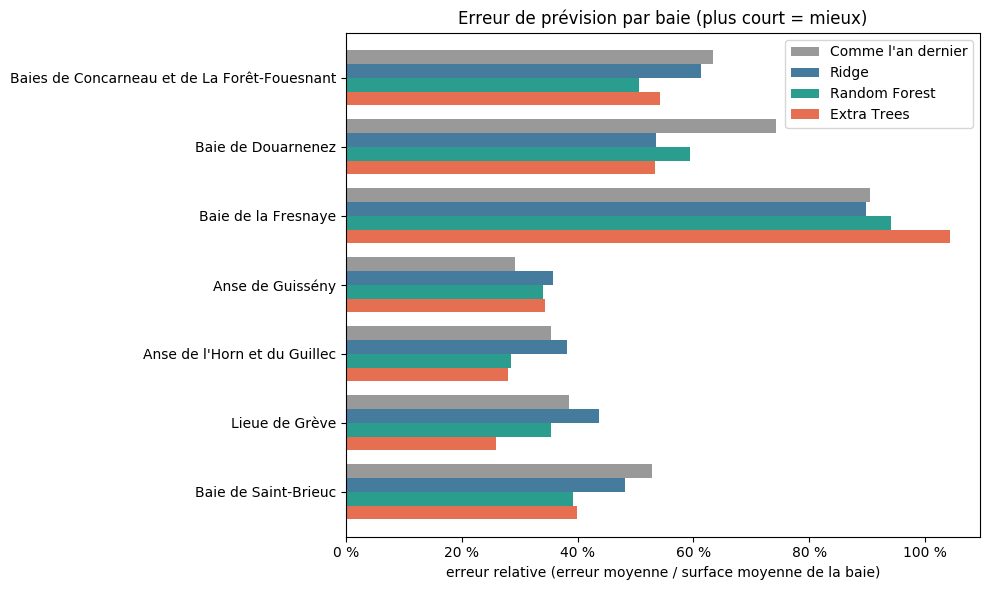

In [6]:
moy = pred.groupby("baie")["vrai"].mean()
err = pd.DataFrame({nom: (pred["pred_" + k] - pred["vrai"]).abs().groupby(pred["baie"]).mean() / moy
                    for k, (nom, _) in {**REF, **MODELES}.items()})
err.index = [noms_baies[b] for b in err.index]
ax = err.plot.barh(figsize=(10, 6), color=[v[1] for v in {**REF, **MODELES}.values()], width=0.8)
ax.invert_yaxis(); ax.set_xlabel("erreur relative (erreur moyenne / surface moyenne de la baie)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: "%.0f %%" % (100 * v)))
ax.set_title("Erreur de prévision par baie (plus court = mieux)")
plt.tight_layout()

## 5. Erreur par année : quelles années sont difficiles ?

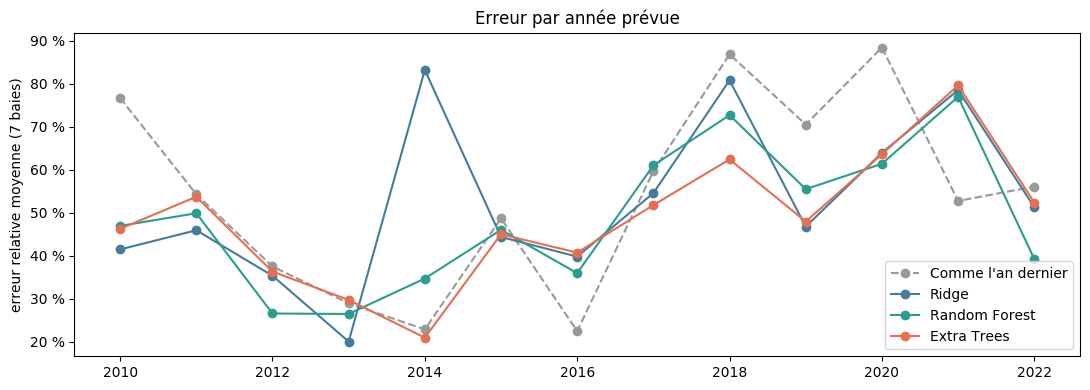

In [7]:
fig, ax = plt.subplots(figsize=(11, 4))
for k, (nom, c) in {**REF, **MODELES}.items():
    e = ((pred["pred_" + k] - pred["vrai"]).abs() / pred["baie"].map(moy)).groupby(pred["annee"]).mean()
    ax.plot(e.index.values, e.values, marker="o", color=c, ls="--" if k in REF else "-", label=nom)
ax.set_ylabel("erreur relative moyenne (7 baies)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: "%.0f %%" % (100 * v)))
ax.legend(); ax.set_title("Erreur par année prévue")
fig.tight_layout()

## 6. Ce que les arbres utilisent

Importance par permutation, mesurée sur des années non vues : on mélange une variable et on regarde
de combien l'erreur augmente. Le calcul prend ~6 minutes : passer `CALCULER = True` pour le relancer.

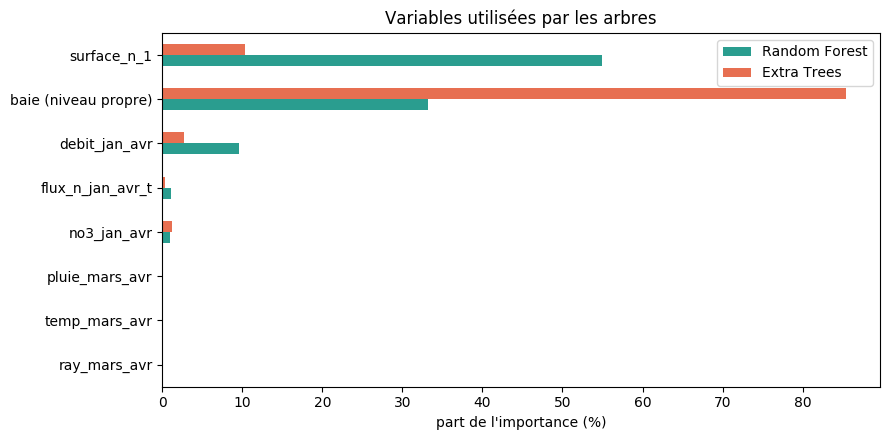

In [8]:
CALCULER = False
if CALCULER:
    imp = pd.DataFrame({nom: importance_hors_echantillon(table, VARIABLES, k)
                        for k, (nom, _) in MODELES.items() if k != "ridge"})
else:  # valeurs obtenues le 2026-11-21 (scripts/baseline_annuel.py --importance)
    imp = pd.DataFrame({
        "Random Forest": {"surface_n_1": 55.0, "baie (niveau propre)": 33.2, "debit_jan_avr": 9.6,
                          "no3_jan_avr": 1.0, "flux_n_jan_avr_t": 1.1, "ray_mars_avr": -1.1,
                          "temp_mars_avr": -1.2, "pluie_mars_avr": -1.1},
        "Extra Trees": {"surface_n_1": 10.3, "baie (niveau propre)": 85.4, "debit_jan_avr": 2.7,
                        "no3_jan_avr": 1.2, "flux_n_jan_avr_t": 0.4, "ray_mars_avr": -0.1,
                        "temp_mars_avr": -0.8, "pluie_mars_avr": -0.4}})
ax = imp.clip(lower=0).sort_values("Random Forest").plot.barh(
    figsize=(9, 4.5), color=[MODELES["random_forest"][1], MODELES["extra_trees"][1]])
ax.set_xlabel("part de l'importance (%)"); ax.set_title("Variables utilisées par les arbres")
plt.tight_layout()

## Ce qu'on retient

- **Les deux forêts battent la Ridge** pour la prévision au 1er mai : environ 62-64 ha d'erreur moyenne
  contre 73 ha, soit +10 à +11 % de mieux que « comme l'an dernier » (+3 % pour la Ridge).
- **Elles gagnent surtout sur les grandes baies** : Saint-Brieuc et la Lieue de Grève.
- **Mais ce sont des prévisions prudentes** : les forêts restent proches du niveau habituel de chaque
  baie. Elles évitent les grosses erreurs (d'où une erreur moyenne plus faible) mais **n'anticipent pas
  les pics** : Saint-Brieuc 2017 et 2019 (880 et 1 145 ha) sont prévus autour de 500 ha. « Comme l'an
  dernier » tombe d'ailleurs un peu plus souvent à ±50 % de la réalité (51 % contre 47-48 %).
- **La Ridge fait parfois des écarts brutaux** (Saint-Brieuc, Lieue de Grève et Horn-Guillec en 2014) :
  une formule linéaire extrapole mal quand une variable sort de l'ordinaire.
- **Leur avantage ne vient pas de l'azote ni de la météo** (moins de 5 % de l'importance) mais de la façon
  de combiner la surface de l'an dernier et le niveau habituel de la baie : après une année extrême,
  elles prévoient un retour vers la normale.
- **Les écarts restent dans la marge d'incertitude** (13 années testées) : il faudra la série mensuelle
  satellite pour départager les modèles et faire parler les facteurs environnementaux.